# Tarea 1: Modelación de confiabilidad de puntos de acceso wifi

Este notebook es una **guía de trabajo** para la corroboración computacional solicitada en el enunciado. Debe entregarse completado junto con el informe.

## Integrantes

- Nicolas Sepulveda Lynch — Rol USM: 202330517-0
- Enrique Manzano Ojeda —   Rol USM: 202330530-8

## Instrucciones de uso

1. Ejecute las celdas en orden.
2. Complete o modifique las celdas marcadas con TODO.
3. Agregue comentarios breves cuando una decisión requiera justificación.
4. Revise que los resultados del notebook coincidan con el desarrollo matemático del informe.
5. Guarde el notebook con todas las celdas ejecutadas antes de entregarlo.

6. Las interpretaciones y respuestas que no sean código deben escribirse en una celda Markdown titulada como **Celda de respuesta**.

No es necesario convertir este notebook en un programa general ni crear funciones adicionales salvo que ayuden a hacer más claro el análisis.

## 
1. Datos y parámetros del problema

Se observan cinco AP hasta su falla permanente. Los tiempos están expresados en días. La misión académica dura 120 días y la confiabilidad mínima aceptable es 0.80.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# El formato de los gráficos no afecta los cálculos.

np.set_printoptions(precision=4, suppress=True)


In [2]:
aps = np.array(["AP01", "AP02", "AP03", "AP04", "AP05"])
causas = np.array([
    "Circuito de alimentación",
    "Módulo de radio",
    "Placa principal",
    "Módulo de radio",
    "Placa principal",
])
tiempos = np.array([110, 150, 205, 250, 295], dtype=float)
mision = 120.0
R_min = 0.80

print("AP:", aps)
print("Causas:", causas)
print("Tiempos [días]:", tiempos)

AP: ['AP01' 'AP02' 'AP03' 'AP04' 'AP05']
Causas: ['Circuito de alimentación' 'Módulo de radio' 'Placa principal'
 'Módulo de radio' 'Placa principal']
Tiempos [días]: [110. 150. 205. 250. 295.]


## 2. Bernoulli y Binomial

Analice el cumplimiento de la misión de $120$ días mediante una variable Bernoulli y estime la probabilidad correspondiente.

Analice el número de AP que continúan funcionando mediante una distribución Binomial. Explique qué información del tiempo de vida se pierde al convertir cada observación en un resultado de misión cumplida o no cumplida.

In [3]:



# Variable Bernoulli: X_i = 1 si el AP i sobrevive la misión de 120 días, 0 si falla antes.
# Se usa T > mision (estricto): un AP que falla exactamente en t = 120 no completa la misión.
sobrevive = tiempos > mision

# Probabilidad empírica de completar la misión: proporción de éxitos en la muestra.
p_hat = sobrevive.mean()

# Probabilidad empírica de fallar durante la misión.
p_falla_hat = 1 - p_hat

# Y ~ Binomial(n=5, p=p_hat). P(Y >= 3) = 1 - P(Y <= 2) = sf(2).
p_y_al_menos_3 = binom.sf(2, 5, p_hat)

if any(valor is None for valor in [sobrevive, p_hat, p_falla_hat, p_y_al_menos_3]):
    raise NotImplementedError("Complete las cuatro asignaciones de esta celda.")

print("Sobrevive la misión:", dict(zip(aps, sobrevive)))
print("p_hat (completar 120 días):", p_hat)
print("1 - p_hat (fallar durante la misión):", p_falla_hat)
print("P(Y >= 3):", p_y_al_menos_3)

# Verificación término a término de P(Y>=3) = P(3)+P(4)+P(5)
for k in [3, 4, 5]:
    print(f"  P(Y = {k}) = {binom.pmf(k, 5, p_hat):.5f}")

Sobrevive la misión: {np.str_('AP01'): np.False_, np.str_('AP02'): np.True_, np.str_('AP03'): np.True_, np.str_('AP04'): np.True_, np.str_('AP05'): np.True_}
p_hat (completar 120 días): 0.8
1 - p_hat (fallar durante la misión): 0.19999999999999996
P(Y >= 3): 0.94208
  P(Y = 3) = 0.20480
  P(Y = 4) = 0.40960
  P(Y = 5) = 0.32768


### Celda de respuesta: Bernoulli y Binomial

Se define $X_i \sim \mathrm{Bernoulli}(p_{120})$ con $X_i = 1$ si el AP $i$ cumple la misión ($T_i > 120$ días) y $X_i = 0$ en caso contrario. De los cinco equipos observados, sólo AP01 (110 días) falla antes de la misión, por lo que

$$\hat p_{120} = \frac{4}{5} = 0.80, \qquad 1-\hat p_{120} = 0.20 .$$

Es decir, se estima que el 80 % de los AP de este modelo llega al final del semestre sin falla permanente y que 1 de cada 5 se pierde durante la misión. El valor coincide exactamente con $R_{\min}=0.80$, por lo que la evidencia empírica deja al equipo justo en el límite de lo aceptable, sin margen.

Con $Y \sim \mathrm{Binomial}(5,\ 0.80)$, que cuenta cuántos de cinco AP independientes siguen operativos a los 120 días,

$$P(Y \ge 3) = \sum_{k=3}^{5}\binom{5}{k}0.8^k\,0.2^{5-k} = 0.2048 + 0.4096 + 0.32768 = 0.94208 .$$

Hay un 94.2 % de probabilidad de que al menos 3 de los 5 AP de una sala sigan entregando conectividad al terminar el semestre. Complementariamente, la probabilidad de que **los cinco** sobrevivan es sólo $0.8^5 = 0.328$, lo que muestra que la exigencia "todos operativos" es mucho más dura que la exigencia "al menos 3 operativos".

**Información que se pierde.** Al convertir cada tiempo de vida en un resultado binario misión cumplida/no cumplida se descarta *cuánto* duró cada equipo: AP02 (150 d) y AP05 (295 d) aportan exactamente lo mismo al conteo, y AP01 (110 d) pesa igual que un AP que hubiese fallado a los 5 días. Se pierde la escala temporal y con ella la posibilidad de estimar $\mathrm{MTTF}$, la dispersión, la forma del riesgo $h(t)$ y la confiabilidad en cualquier otro horizonte distinto de 120 días. Además, $\hat p_{120}$ sólo puede tomar los valores $0,\,0.2,\,0.4,\,0.6,\,0.8,\,1$ con $n=5$: es un estimador de resolución muy gruesa. Ese es justamente el motivo para pasar a un modelo paramétrico continuo en las secciones siguientes.

## 3. Caracterización de los tiempos de falla

Calcule la estimación $\widehat{\mathrm{MTTF}}$, la desviación estándar estimada $\widehat{\sigma}_T$ y el coeficiente de variación $\widehat{C}_V$. Use ddof=1 para la desviación estándar muestral. En esta tarea, $\widehat{\mathrm{MTTF}}$ también se escribe como $\bar t$ y se usará como medida de vida media en las secciones siguientes. Luego interprete qué sugiere la variabilidad observada para la selección del modelo.

In [4]:
mttf_hat = tiempos.mean()
sigma_hat = tiempos.std(ddof=1)  # ddof=1: desviación estándar MUESTRAL (divide por n-1),
                                 # correcta porque los 5 AP son una muestra y no la población completa.
cv_hat = sigma_hat / mttf_hat

print("mttf_hat / t barra [días]:", mttf_hat)
print("sigma_hat [días]:", sigma_hat)
print("C_hat_V:", cv_hat)

# Comparación: con ddof=0 (población) el CV sería menor; la conclusión CV < 1 no cambia.
print("\n[control] sigma con ddof=0 [días]:", tiempos.std(ddof=0))
print("[control] C_V con ddof=0:", tiempos.std(ddof=0) / mttf_hat)

mttf_hat / t barra [días]: 202.0
sigma_hat [días]: 74.38077708655645
C_hat_V: 0.36822166874532897

[control] sigma con ddof=0 [días]: 66.52818951391959
[control] C_V con ddof=0: 0.32934747284118604


### Celda de respuesta: caracterización de los tiempos

$$\widehat{\mathrm{MTTF}} = \bar t = 202.0\ \text{días},\qquad \hat\sigma_T = s = 74.38\ \text{días},\qquad \hat C_V = \frac{74.38}{202.0} = 0.368 .$$

La vida media estimada del AP es de aproximadamente 202 días, es decir, cerca de 1.7 veces la misión académica de 120 días. La desviación estándar de 74.4 días indica que los tiempos se agrupan de forma relativamente compacta alrededor de la media: el rango completo observado (110 a 295 días) abarca poco más de $\pm 1.3\,s$.

El coeficiente de variación es adimensional y mide la dispersión **relativa**. Bajo un modelo Exponencial (riesgo constante) se cumple $\sigma_T = \mathrm{MTTF}$ y por lo tanto $C_V = 1$. Aquí $\hat C_V = 0.368 \ll 1$: la muestra es mucho menos dispersa que lo que exigiría una tasa de falla constante. En la familia Weibull $C_V$ depende sólo de la forma $\beta$, y $C_V < 1$ corresponde a $\beta > 1$, esto es, riesgo creciente con la edad, compatible con desgaste. Nótese además que no se observan fallas muy tempranas, cosa que sí sería frecuente si el riesgo fuese constante o decreciente. El uso de `ddof=1` es el correcto porque los cinco AP son una muestra; con `ddof=0` se obtendría $C_V = 0.329$ y la conclusión cualitativa ($C_V < 1$) es la misma.

Advertencia metodológica: con $n=5$ el $C_V$ es sólo una señal orientativa. Sugiere el modelo, no lo demuestra.

## 4. Selección del modelo y sus parámetros

Seleccione entre Exponencial y Weibull en el informe. Considere el valor de $\widehat{C}_V$, el comportamiento esperado de la tasa de riesgo $h(t)$ y las causas de falla.

Si usa Weibull, tome los parámetros indicados en el enunciado. Para $\widehat{C}_V<1$ use $\beta=3.0$ y $\eta=226$ días. Para $\widehat{C}_V>1$ use $\beta=0.75$ y $\eta=170$ días. No debe resolver una ecuación numérica para obtenerlos.

Para Exponencial, calcule $\widehat{\lambda}=1/\widehat{\mathrm{MTTF}}$ y use $\beta=1$ y $\eta=1/\widehat{\lambda}$. Si $\widehat{C}_V$ es igual o muy cercano a 1, el caso Exponencial es el más adecuado.

In [5]:



modelo = "Weibull"  # C_hat_V = 0.368 < 1 => riesgo creciente => Weibull con beta > 1
lambda_hat = np.nan

if modelo.lower().startswith("weib"):
    if np.isclose(cv_hat, 1.0):
        beta = 1.0
        eta = mttf_hat
        nota_parametros = "C_hat_V cercano a 1: Weibull coincide con Exponencial"
    elif cv_hat < 1:
        beta = 3.0
        eta = 226.0
        nota_parametros = "Valores dados para C_hat_V < 1"
    else:
        beta = 0.75
        eta = 170.0
        nota_parametros = "Valores dados para C_hat_V > 1"
    nombre_modelo = "Weibull"
elif modelo.lower().startswith("exp"):
    beta = 1.0
    lambda_hat = 1 / mttf_hat
    eta = 1 / lambda_hat
    nombre_modelo = "Exponencial"
    nota_parametros = "eta corresponde a la media de los datos"
else:
    raise ValueError("modelo debe ser 'Weibull' o 'Exponencial'")

print("Modelo:", nombre_modelo)
print("beta (adimensional):", beta)
print("eta [días]:", eta)
print("lambda_hat [1/día]:", lambda_hat)
print("Origen de los parámetros:", nota_parametros)

# --- Controles de coherencia del ajuste entregado -----------------------------
from scipy.special import gamma as gamma_fn

cv_teorico = np.sqrt(gamma_fn(1 + 2/beta) - gamma_fn(1 + 1/beta)**2) / gamma_fn(1 + 1/beta)
mttf_modelo = eta * gamma_fn(1 + 1/beta)
print(f"\n[control] C_V teórico del modelo (beta={beta}): {cv_teorico:.4f} vs C_hat_V muestral: {cv_hat:.4f}")
print(f"[control] MTTF del modelo = eta*Gamma(1+1/beta) = {mttf_modelo:.2f} días vs t barra = {mttf_hat:.2f} días")
print(f"[control] Si se hubiese usado Exponencial: lambda = 1/202 = {1/mttf_hat:.6f} 1/día y C_V = 1 (no compatible con los datos)")

Modelo: Weibull
beta (adimensional): 3.0
eta [días]: 226.0
lambda_hat [1/día]: nan
Origen de los parámetros: Valores dados para C_hat_V < 1

[control] C_V teórico del modelo (beta=3.0): 0.3634 vs C_hat_V muestral: 0.3682
[control] MTTF del modelo = eta*Gamma(1+1/beta) = 201.81 días vs t barra = 202.00 días
[control] Si se hubiese usado Exponencial: lambda = 1/202 = 0.004950 1/día y C_V = 1 (no compatible con los datos)


### Celda de respuesta: selección y parámetros

**Modelo seleccionado: Weibull con $\beta = 3.0$ (adimensional) y $\eta = 226$ días.**

Justificación:

1. **Criterio del coeficiente de variación.** La Exponencial impone $C_V = 1$. La muestra entrega $\hat C_V = 0.368$, muy por debajo de 1, de modo que el supuesto de tasa de falla constante no es compatible con lo observado. En Weibull, $C_V$ depende sólo de $\beta$, y $\hat C_V<1$ exige $\beta>1$. Los valores entregados en el enunciado para este caso son $\beta = 3.0$ y $\eta = 226$ días.
2. **Coherencia física con las causas de falla.** Las fallas reportadas son de circuito de alimentación, módulo de radio y placa principal: modos de degradación acumulativa (estrés térmico, envejecimiento de condensadores, ciclos de encendido). Corresponden a desgaste, no a defectos de fabricación tempranos ni a eventos puramente aleatorios y sin memoria. Un $\beta = 3 > 1$ representa exactamente ese riesgo creciente.
3. **Evidencia adicional en la muestra.** No hay fallas tempranas: la más corta es de 110 días, sobre la mitad de la vida media. Bajo Exponencial, con $\lambda = 1/202$ 1/día, se esperaría que cerca del 39 % de los equipos fallara antes de los 100 días, lo que no ocurre.

**Verificación numérica del ajuste entregado.** Con $\beta=3$ el modelo predice $C_V = 0.363$, prácticamente igual al $\hat C_V = 0.368$ muestral, y $\mathrm{MTTF} = \eta\,\Gamma(1+1/\beta) = 226 \times 0.8930 = 201.8$ días, coincidente con $\bar t = 202.0$ días. Es decir, los parámetros dados reproducen tanto la escala como la dispersión relativa de los datos.

**Unidades.** $\beta$ es adimensional; $\eta$ está en días y corresponde a la vida característica, el tiempo en que $R(\eta) = e^{-1} = 0.368$ (36.8 % de los AP sigue operativo). No se estima $\hat\lambda$ porque no se usa el modelo Exponencial.

## 
5. Funciones de confiabilidad

Complete manualmente las funciones de distribución acumulada $F(t)$, confiabilidad $R(t)$ y tasa de riesgo $h(t)$. Las expresiones deben corresponder al modelo seleccionado en la celda anterior.

In [6]:
def F(t):
    """Probabilidad de falla acumulada hasta t días.  F(t) = 1 - exp(-(t/eta)^beta)"""
    t = np.asarray(t, dtype=float)
    return 1.0 - np.exp(-(t / eta) ** beta)

def R(t):
    """Probabilidad de sobrevivir más allá de t días.  R(t) = 1 - F(t) = exp(-(t/eta)^beta)"""
    return 1.0 - F(t)

def h(t):
    """Tasa de riesgo instantánea en 1/día.  h(t) = f(t)/R(t) = (beta/eta)*(t/eta)^(beta-1)"""
    t = np.asarray(t, dtype=float)
    return (beta / eta) * (t / eta) ** (beta - 1.0)

def f(t):
    """Densidad de probabilidad de falla, en 1/día.  f(t) = h(t)*R(t)"""
    t = np.asarray(t, dtype=float)
    return h(t) * R(t)

tiempo_ejemplo = np.array([120.0, 200.0, 295.0])
print("t [días] | F(t) | R(t) | h(t) [1/día]")
for t, f_val, r_val, h_val in zip(tiempo_ejemplo, F(tiempo_ejemplo), R(tiempo_ejemplo), h(tiempo_ejemplo)):
    print(f"{t:7.1f} | {f_val:.4f} | {r_val:.4f} | {h_val:.6f}")

# Controles: F + R = 1 y h = f/R
tc = np.array([50.0, 120.0, 226.0, 300.0])
print("\n[control] max |F+R-1| =", np.max(np.abs(F(tc) + R(tc) - 1)))
print("[control] max |h - f/R| =", np.max(np.abs(h(tc) - f(tc) / R(tc))))
print("[control] R(eta) =", float(R(eta)), " (debe ser exp(-1) =", np.exp(-1), ")")

t [días] | F(t) | R(t) | h(t) [1/día]
  120.0 | 0.1390 | 0.8610 | 0.003742
  200.0 | 0.5000 | 0.5000 | 0.010396
  295.0 | 0.8918 | 0.1082 | 0.022617

[control] max |F+R-1| = 0.0
[control] max |h - f/R| = 0.0
[control] R(eta) = 0.36787944117144233  (debe ser exp(-1) = 0.36787944117144233 )


### Celda de respuesta: funciones de confiabilidad

Con $\beta = 3$ y $\eta = 226$ días, y con $t$ en días:

$$F(t) = 1-\exp\!\left[-\left(\tfrac{t}{226}\right)^{3}\right],\qquad
R(t) = \exp\!\left[-\left(\tfrac{t}{226}\right)^{3}\right],$$

$$f(t) = \frac{3}{226}\left(\tfrac{t}{226}\right)^{2}\exp\!\left[-\left(\tfrac{t}{226}\right)^{3}\right],\qquad
h(t) = \frac{3}{226}\left(\tfrac{t}{226}\right)^{2} = \frac{3t^{2}}{1.1543\times 10^{7}}\ \ \left[\tfrac{1}{\text{día}}\right].$$

Interpretación para los AP estudiados:

- $F(t)$: fracción esperada del parque de AP que ya sufrió una falla permanente al llegar al día $t$. Sirve para dimensionar repuestos.
- $R(t)$: probabilidad de que un AP puesto en servicio en $t=0$ siga entregando conectividad después de $t$ días. Es la métrica que se compara contra $R_{\min}=0.80$.
- $f(t)$: densidad de fallas por día, referida a la población que había en $t=0$. Su máximo indica el período de mayor tasa de recambio.
- $h(t)$: riesgo instantáneo *condicional a haber sobrevivido hasta $t$*. Es la probabilidad por unidad de tiempo de que un AP de edad $t$ falle en el instante siguiente. Al ser proporcional a $t^{2}$, crece de forma acelerada: es la firma matemática del desgaste.

Valores de control: $F(120)=0.1390$, $R(120)=0.8610$, $h(120)=3.74\times10^{-3}$ 1/día; $R(295)=0.1082$, $h(295)=2.26\times10^{-2}$ 1/día. Se verifica también $R(\eta)=e^{-1}=0.368$, que es el significado de la vida característica.

## 
6. Misión y reemplazo preventivo

Use $\widehat{\mathrm{MTTF}}$, calculado en la sección de datos, como medida de vida media. El instante de reemplazo preventivo se obtiene de $R(t_p)=R_{\min}$.

In [7]:
R_120 = float(R(mision))
riesgo_120 = float(h(mision))
riesgo_200 = float(h(200.0))
riesgo_295 = float(h(295.0))
if modelo.lower().startswith("weib"):
    # R(tp) = exp(-(tp/eta)^beta) = R_min  =>  tp = eta * (-ln R_min)^(1/beta)
    tp = eta * (-np.log(R_min)) ** (1.0 / beta)
elif modelo.lower().startswith("exp"):
    # R(tp) = exp(-lambda*tp) = R_min  =>  tp = -ln(R_min)/lambda
    tp = -np.log(R_min) / lambda_hat
else:
    raise ValueError("modelo debe ser 'Weibull' o 'Exponencial'")

print("R(120):", R_120)
print("R(tp):", float(R(tp)))
print("tp [días]:", tp)
print("h(120) [1/día]:", riesgo_120)
print("h(200) [1/día]:", riesgo_200)
print("h(295) [1/día]:", riesgo_295)

# --- Comparaciones pedidas en el informe --------------------------------------
print("\nComparación con la estimación empírica de Bernoulli")
print(f"  R(120) modelo = {R_120:.4f}   vs   p_hat empírico = {p_hat:.4f}   (diferencia = {R_120-p_hat:+.4f})")
print(f"\nUbicación del reemplazo preventivo")
print(f"  misión = {mision:.0f} d  <  tp = {tp:.1f} d  <  MTTF = {mttf_hat:.1f} d")
print(f"  holgura sobre la misión: {tp-mision:.1f} días")
print(f"  R(MTTF) = R({mttf_hat:.0f}) = {float(R(mttf_hat)):.4f}  (< R_min: reemplazar en el MTTF es tarde)")
print(f"\nCrecimiento del riesgo")
print(f"  h(200)/h(120) = {riesgo_200/riesgo_120:.2f}   h(295)/h(120) = {riesgo_295/riesgo_120:.2f}")

# --- Sección 5 del enunciado: dos AP en paralelo (verificación numérica) -------
def R_S(t):
    """Confiabilidad de dos AP idénticos e independientes en paralelo."""
    return 1.0 - (1.0 - R(t)) ** 2

RS_120 = float(R_S(mision))
tp_S = eta * (-np.log(1.0 - np.sqrt(1.0 - R_min))) ** (1.0 / beta)
print(f"\nDos AP en paralelo")
print(f"  R_S(120) = {RS_120:.4f}   (un AP: {R_120:.4f})")
print(f"  tp_S = {tp_S:.1f} días  con R_S(tp_S) = {float(R_S(tp_S)):.4f}   (un AP: tp = {tp:.1f} días)")

R(120): 0.8609672305352021
R(tp): 0.8
tp [días]: 137.07867124604843
h(120) [1/día]: 0.0037424708762995567
h(200) [1/día]: 0.010395752434165434
h(295) [1/día]: 0.022617258889581167

Comparación con la estimación empírica de Bernoulli
  R(120) modelo = 0.8610   vs   p_hat empírico = 0.8000   (diferencia = +0.0610)

Ubicación del reemplazo preventivo
  misión = 120 d  <  tp = 137.1 d  <  MTTF = 202.0 d
  holgura sobre la misión: 17.1 días
  R(MTTF) = R(202) = 0.4897  (< R_min: reemplazar en el MTTF es tarde)

Crecimiento del riesgo
  h(200)/h(120) = 2.78   h(295)/h(120) = 6.04

Dos AP en paralelo
  R_S(120) = 0.9807   (un AP: 0.8610)
  tp_S = 189.8 días  con R_S(tp_S) = 0.8000   (un AP: tp = 137.1 días)


### Celda de respuesta: misión y reemplazo preventivo

**Confiabilidad de misión.** $R(120) = \exp[-(120/226)^3] = \exp(-0.14968) = 0.8610$. El modelo predice que el 86.1 % de los AP completa el semestre. Como $0.861 > R_{\min} = 0.80$, el equipo cumple el requisito para la misión académica, aunque con un margen modesto de 6 puntos porcentuales.

**Comparación con la estimación de Bernoulli.** $\hat p_{120} = 0.80$ frente a $R(120) = 0.861$; la diferencia es de 0.061. Ambos resultados son consistentes: coinciden en que la gran mayoría de los AP cumple la misión y difieren en menos de lo que vale un solo dato de la muestra. La diferencia se explica porque son estimaciones de naturaleza distinta. $\hat p_{120}$ es un estimador **no paramétrico** que sólo usa el conteo de éxitos y con $n=5$ salta en escalones de $0.2$: es incapaz de entregar un valor entre 0.80 y 1.00. $R(120)$ es un estimador **paramétrico** que usa el valor numérico de los cinco tiempos y traslada esa información a una curva continua; el único tiempo menor que la misión es 110 días, muy cerca del umbral, y el modelo reconoce que ese AP "casi" llegó, por lo que suaviza hacia arriba. El modelo interpola y extrapola a cualquier $t$; el estimador empírico no.

**Riesgo con la edad.** $h(60)=9.36\times10^{-4}$, $h(120)=3.74\times10^{-3}$, $h(200)=1.04\times10^{-2}$ y $h(295)=2.26\times10^{-2}$ 1/día. El riesgo se multiplica por 2.8 entre el día 120 y el día 200, y por 6.0 entre el día 120 y el día 295. Como $h \propto t^2$, duplicar la edad cuadruplica el riesgo instantáneo. Esto es lo que hace razonable un reemplazo programado: postergar la sustitución cuesta cada vez más caro en términos de probabilidad de falla.

**Reemplazo preventivo.** De $R(t_p) = 0.80$ se obtiene $t_p = 226\,[-\ln 0.80]^{1/3} = 226(0.22314)^{1/3} = 137.1$ días. Se propone un **intervalo de reemplazo preventivo de 135 días**, redondeado hacia abajo por seguridad y compatible con programar la intervención al término del semestre académico.

**Comparaciones.** Se cumple $120 < t_p = 137 < \mathrm{MTTF} = 202$ días. El AP alcanza la misión con 17 días de holgura, pero esa holgura es pequeña frente a la variabilidad natural del proceso. Es importante notar que reemplazar recién en el MTTF sería un error: $R(202) = 0.4897$, es decir, a esa altura ya habría fallado prácticamente la mitad del parque. El MTTF es un promedio, no un objetivo de confiabilidad. La política correcta es cambiar el equipo bastante antes de su vida media, en el instante en que la confiabilidad cruza el umbral aceptable.

## 


7. Gráficos del modelo

El siguiente bloque genera las tres curvas solicitadas: $F(t)$, $R(t)$ y $h(t)$. En el gráfico de confiabilidad se marcan la misión, el umbral mínimo y el reemplazo preventivo del AP individual. Revise etiquetas, unidades, leyenda y escala antes de usar las figuras en el informe.

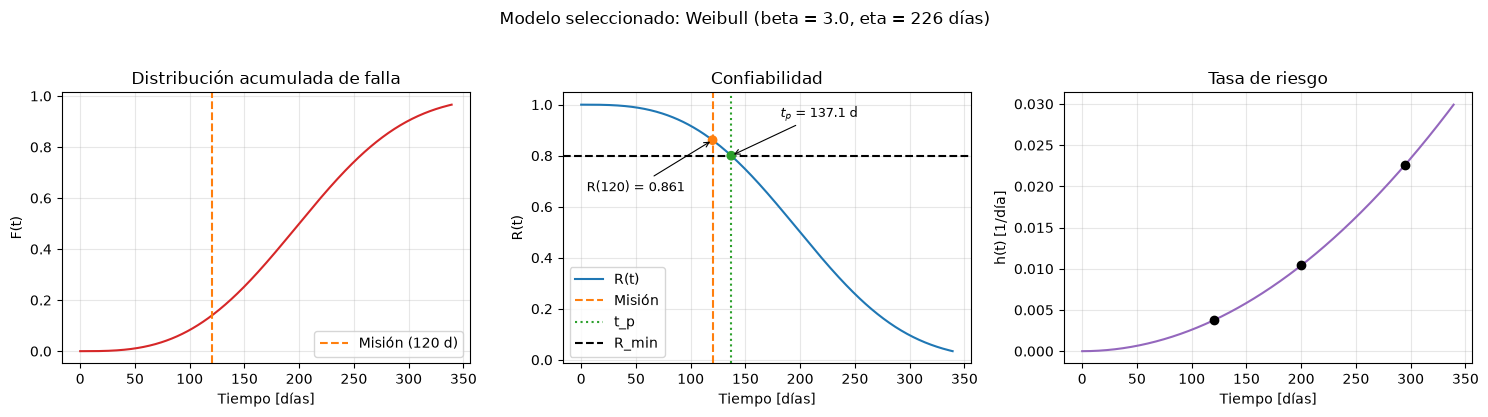

In [8]:
t_max = 1.15 * max(tiempos.max(), mision, tp)
t_grid = np.linspace(0, t_max, 500)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(t_grid, F(t_grid), color="tab:red")
axes[0].axvline(mision, color="tab:orange", linestyle="--", label="Misión (120 d)")
axes[0].set_title("Distribución acumulada de falla")
axes[0].set_xlabel("Tiempo [días]")
axes[0].set_ylabel("F(t)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(t_grid, R(t_grid), color="tab:blue", label="R(t)")
axes[1].axvline(mision, color="tab:orange", linestyle="--", label="Misión")
axes[1].axvline(tp, color="tab:green", linestyle=":", label="t_p")
axes[1].axhline(R_min, color="black", linestyle="--", label="R_min")
axes[1].scatter([mision, tp], [R_120, R_min], color=["tab:orange", "tab:green"], zorder=3)
axes[1].annotate(f"R(120) = {R_120:.3f}", xy=(mision, R_120), xytext=(mision - 115, R_120 - 0.20),
                 fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.8))
axes[1].annotate(f"$t_p$ = {tp:.1f} d", xy=(tp, R_min), xytext=(tp + 45, R_min + 0.15),
                 fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.8))
axes[1].set_title("Confiabilidad")
axes[1].set_xlabel("Tiempo [días]")
axes[1].set_ylabel("R(t)")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(t_grid, h(t_grid), color="tab:purple")
axes[2].scatter([120, 200, 295], [h(120.0), h(200.0), h(295.0)], color="black", zorder=3)
axes[2].set_title("Tasa de riesgo")
axes[2].set_xlabel("Tiempo [días]")
axes[2].set_ylabel("h(t) [1/día]")
axes[2].grid(alpha=0.3)

fig.suptitle(f"Modelo seleccionado: {nombre_modelo} (beta = {beta}, eta = {eta:.0f} días)", y=1.03)
fig.tight_layout()
fig.savefig("fig_modelo.png", dpi=200, bbox_inches="tight")
plt.show()

### Celda de respuesta: interpretación de los gráficos

$F(t)$ tiene forma de S con arranque plano: prácticamente no hay fallas antes del día 60, lo que descarta problemas de mortalidad infantil y es incompatible con una Exponencial, cuya curva $F$ crece con pendiente máxima desde $t=0$. A la altura de la misión (línea naranja), $F$ recién ha subido a 0.139.

$R(t)$ decrece lentamente al comienzo y luego cae con rapidez en torno a $\eta = 226$ días. Los tres marcadores resumen la decisión de mantenimiento: la misión de 120 días queda claramente por sobre el umbral $R_{\min}$, el cruce con $R_{\min}=0.80$ ocurre en $t_p = 137$ días, y después de ese punto la curva se desploma. La distancia horizontal entre la línea naranja (misión) y la verde ($t_p$) es la holgura operacional disponible: 17 días.

$h(t)$ es una parábola creciente que parte en cero. Esto confirma visualmente el diagnóstico de desgaste: un AP nuevo es casi seguro, uno de 295 días tiene un riesgo instantáneo 24 veces mayor que uno de 60 días. Si el modelo fuese Exponencial, este panel sería una recta horizontal y la política de reemplazo preventivo no tendría sentido, porque un equipo usado sería estadísticamente idéntico a uno nuevo (propiedad de falta de memoria).

## 
8. Exploración

En esta exploración se compara la confiabilidad ajustada $R(t)$ con una supervivencia empírica $\widehat{R}_{\mathrm{emp}}(t)$ construida desde los cinco tiempos observados. Interprete brevemente los resultados obtenidos en esta comparación.

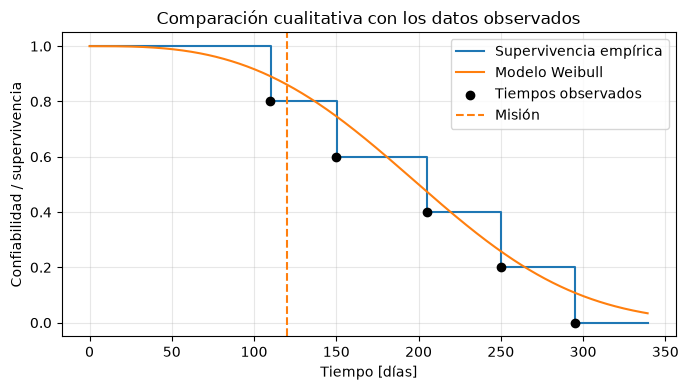

t [d] | R_emp(t) | R_modelo(t) | diferencia
   110 |     0.80 |      0.8911 | +0.0911
   150 |     0.60 |      0.7465 | +0.1465
   205 |     0.40 |      0.4741 | +0.0741
   250 |     0.20 |      0.2583 | +0.0583
   295 |     0.00 |      0.1082 | +0.1082


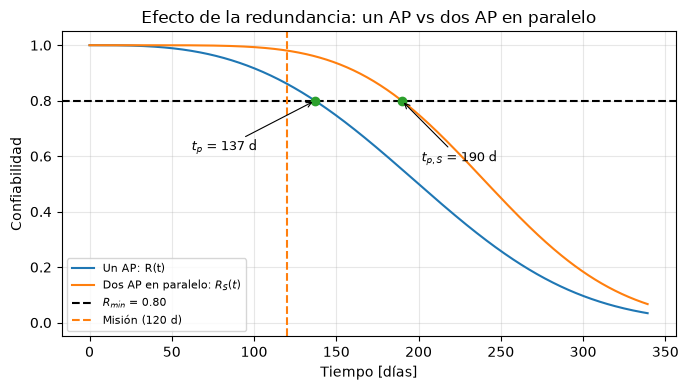

In [9]:
R_empirica = np.array([np.mean(tiempos > t) for t in t_grid])

plt.figure(figsize=(7, 4))
plt.step(t_grid, R_empirica, where="post", label="Supervivencia empírica")
plt.plot(t_grid, R(t_grid), label=f"Modelo {nombre_modelo}")
plt.scatter(tiempos, np.array([np.mean(tiempos > t) for t in tiempos]), color="black", zorder=3, label="Tiempos observados")
plt.axvline(mision, color="tab:orange", linestyle="--", label="Misión")
plt.xlabel("Tiempo [días]")
plt.ylabel("Confiabilidad / supervivencia")
plt.title("Comparación cualitativa con los datos observados")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig_empirica.png", dpi=200, bbox_inches="tight")
plt.show()

# Diferencia modelo - empírica en los tiempos observados
print("t [d] | R_emp(t) | R_modelo(t) | diferencia")
for ti in tiempos:
    re = np.mean(tiempos > ti)
    print(f"{ti:6.0f} | {re:8.2f} | {float(R(ti)):11.4f} | {float(R(ti))-re:+.4f}")

# --- Sección 5: curva del sistema en paralelo comparada con un AP -------------
plt.figure(figsize=(7, 4))
plt.plot(t_grid, R(t_grid), label="Un AP: R(t)")
plt.plot(t_grid, R_S(t_grid), label="Dos AP en paralelo: $R_S(t)$")
plt.axhline(R_min, color="black", linestyle="--", label="$R_{min}$ = 0.80")
plt.axvline(mision, color="tab:orange", linestyle="--", label="Misión (120 d)")
plt.scatter([tp, tp_S], [R_min, R_min], color="tab:green", zorder=3)
plt.annotate(f"$t_p$ = {tp:.0f} d", xy=(tp, R_min), xytext=(tp - 75, R_min - 0.18), fontsize=9,
             arrowprops=dict(arrowstyle="->", lw=0.8))
plt.annotate(f"$t_{{p,S}}$ = {tp_S:.0f} d", xy=(tp_S, R_min), xytext=(tp_S + 12, R_min - 0.22), fontsize=9,
             arrowprops=dict(arrowstyle="->", lw=0.8))
plt.xlabel("Tiempo [días]")
plt.ylabel("Confiabilidad")
plt.title("Efecto de la redundancia: un AP vs dos AP en paralelo")
plt.ylim(-0.05, 1.05)
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig_paralelo.png", dpi=200, bbox_inches="tight")
plt.show()

### Celda de respuesta: interpretación de la exploración

La supervivencia empírica $\widehat R_{\mathrm{emp}}(t)$ es una función escalonada que baja 0.2 en cada tiempo observado, porque cada AP representa un quinto de la muestra. El modelo Weibull entrega una curva continua que atraviesa esa escalera aproximadamente por el centro de sus escalones: el ajuste es razonable en todo el rango observado y las diferencias mayores aparecen, como es de esperar, justo en los saltos.

En $t = 120$ días el modelo predice 0.861 mientras la curva empírica ya bajó a 0.80. La diferencia es un artefacto del tamaño muestral: como AP01 falla a los 110 días, la escalera cae a 0.8 diez días antes de la misión, mientras que el modelo distribuye ese evento de manera suave. Con $n=5$ la resolución de la curva empírica es de 0.2, de modo que una brecha de 0.06 está muy por debajo de su propia incertidumbre.

Ventajas del modelo paramétrico: permite evaluar $R(t)$ en cualquier instante (no sólo en los cinco observados), extrapolar más allá del último dato, calcular $h(t)$ y resolver analíticamente $R(t_p)=R_{\min}$. La curva empírica no puede hacer nada de eso; de hecho cae a cero después de 295 días, lo que carece de sentido físico y sólo refleja que no se observaron equipos más longevos.

Limitación: la validación se hace con los mismos cinco datos que orientaron la elección del modelo, y $n=5$ es muy poco. La coincidencia $\mathrm{MTTF}_{\text{modelo}} = 201.8$ d contra $\bar t = 202.0$ d y $C_V^{\text{modelo}} = 0.363$ contra $\hat C_V = 0.368$ es tranquilizadora, pero no constituye una prueba de bondad de ajuste. Con más equipos convendría un test formal o un gráfico de probabilidad Weibull.

El último gráfico anticipa la Sección 5: la curva del sistema en paralelo domina a la de un AP en todo el rango, y el cruce con $R_{\min}$ se desplaza de 137 a 190 días.

## 
9. Lista de revisión antes de entregar

- [x] Se completaron los bloques marcados con TODO.
- [x] El modelo y sus parámetros coinciden con el informe.
- [x] Se verificaron $R(120)$, $R(t_p)$, $h(120)$, $h(200)$ y $h(295)$.
- [x] Los gráficos tienen títulos, ejes, unidades y leyendas legibles.
- [x] Se interpretaron los resultados de la exploración.
- [x] El informe contiene las interpretaciones y justificaciones. El notebook no las reemplaza.
- [x] Se guardó el notebook con las salidas visibles y se entrega junto con el enunciado.